Берём датасет с МРТ мозга. План работы: загружаем и подготавливаем данные, обучаем свою CNN, обучаем предобученный resnet18, сравниваем результаты.

In [1]:
# 1. Импорты и настройки
%pip install kagglehub pillow --quiet

import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


Подключаю библиотеки для работы со всеми нужными файлами. Фиксирую SEED = 42, чтобы случайные операции можно было повторить

In [2]:
# 2. Загрузка датасета
import kagglehub
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

for root, dirs, files in os.walk(path):
    if root.count(os.sep) - path.count(os.sep) < 2:
        print(root, "| подпапок:", len(dirs), "| файлов:", len(files))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
/kaggle/input/brain-tumor-mri-dataset | подпапок: 2 | файлов: 0
/kaggle/input/brain-tumor-mri-dataset/Training | подпапок: 4 | файлов: 0
/kaggle/input/brain-tumor-mri-dataset/Testing | подпапок: 4 | файлов: 0


Скачиваем датасет и смотрим структуру папок. В нём две части: обучающая и тестовая. В каждой по 4 папки, по одной на каждый класс.

In [3]:
# 3. Загрузка изображений в память
IMG_SIZE = 128
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")
classes = sorted(os.listdir(TRAIN_DIR))
print(classes)

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        files = sorted(os.listdir(os.path.join(root, cls)))[:per_class]
        for name in files:
            img = Image.open(os.path.join(root, cls, name)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img)); labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

X_train_all, y_train_all = load_folder(TRAIN_DIR, per_class=1000)
X_test, y_test = load_folder(TEST_DIR, per_class=300)
print(X_train_all.shape, X_test.shape)

['glioma', 'meningioma', 'notumor', 'pituitary']
(4000, 128, 128, 3) (1200, 128, 128, 3)


Задаю размер изображений 128 на 128 пикселей и получаю названия классов из папок обучающей выборки. Функция load_folder() открывает изображения, переводит их в RGB, меняет размер и сохраняет вместе с метками классов. Для обучающей и тестовой выборок отдельно загружаются изображения и соответствующие названия классов; ограничение per_class позволяет при необходимости уменьшить число файлов каждого класса.

In [4]:
# 4. Разбиение на train/val, нормализация
classes = list(classes)
class_to_idx = {c: i for i, c in enumerate(classes)}
y_train_enc = np.array([class_to_idx[c] for c in y_train_all])
y_test_enc  = np.array([class_to_idx[c] for c in y_test])

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_enc, test_size=0.2, random_state=SEED, stratify=y_train_enc)

# нормализация по train: вычитаем среднее, делим на std
f = X_train.astype(np.float32) / 255.0
mean, std = f.mean(axis=(0, 1, 2)), f.std(axis=(0, 1, 2))

train_tfms = T.Compose([T.ToPILImage(), T.RandomHorizontalFlip(), T.RandomRotation(10),
                        T.ColorJitter(brightness=0.1, contrast=0.1),
                        T.ToTensor(), T.Normalize(mean, std)])
eval_tfms  = T.Compose([T.ToPILImage(), T.ToTensor(), T.Normalize(mean, std)])

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self): return len(self.images)
    def __getitem__(self, i): return self.transform(self.images[i]), int(self.labels[i])

BATCH_SIZE = 64
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms), BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),  BATCH_SIZE)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms), BATCH_SIZE)

Перевожу названия классов в числовые метки, так как нейронная сеть работает с числами. Обучающую выборку делю на train и val в пропорции 80/20, сохраняя доли классов; тестовую выборку оставляю для итоговой проверки. Рассчитываю среднее и стандартное отклонение по обучающим изображениям и использую их для нормализации. Для train добавляю аугментации — например, случайное отражение и небольшой поворот, а для val и test оставляю только стандартную обработку. Dataset выдаёт изображение с меткой, а DataLoader передаёт данные модели батчами по 64 изображения.

In [5]:
# 5. Собственная CNN
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (IMG_SIZE // 16) ** 2, 256), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

m = SimpleCNN(len(classes)).to(device)
print(m(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)
print(sum(p.numel() for p in m.parameters()), "параметров")

torch.Size([2, 4])
2339972 параметров


Создаю собственную свёрточную сеть SimpleCNN. Она состоит из четырёх блоков со свёрткой, BatchNorm, ReLU и MaxPool, которые постепенно извлекают признаки и уменьшают размер карт признаков. Затем признаки преобразуются в вектор и поступают в полносвязные слои. Dropout помогает уменьшить переобучение, а последний слой выдаёт четыре оценки — по одной на каждый класс. В конце проверяю на случайном входе, что форма выхода соответствует количеству изображений и классов.

In [6]:
# 6. Функции обучения и оценки
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return loss_sum / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss_sum += criterion(out, yb).item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy()); y_pred.extend(pred.cpu().numpy())
    return loss_sum / total, correct / total, np.array(y_true), np.array(y_pred)

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3, weight_decay=0.0, patience=4, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "time": []}
    best_loss, best_state, no_improve = float("inf"), None, 0

    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0
        for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_acc, dt]):
            hist[k].append(v)
        print(f"[{title}] Ep {ep+1:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.1f}s")

        if va_loss < best_loss - 1e-4:
            best_loss, best_state, no_improve = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print("Early stopping"); break

    model.load_state_dict(best_state)
    return hist

Определяю общие функции обучения и проверки, которые затем использую для обеих моделей. Во время обучения модель делает предсказание, рассчитывает ошибку, вычисляет градиенты и обновляет параметры с помощью оптимизатора. При оценке параметры не изменяются, а собираются предсказания и рассчитывается точность. Функция fit() запускает обучение по эпохам, следит за результатом на валидации, при необходимости уменьшает скорость обучения и останавливает процесс, если качество перестаёт улучшаться. Она сохраняет параметры лучшей версии модели и историю метрик.

In [7]:
# 7. Обучение SimpleCNN
cnn_model = SimpleCNN(len(classes)).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader, epochs=15, lr=1e-3, weight_decay=1e-5, patience=4, title="SimpleCNN")

[SimpleCNN] Ep 01/15 | train loss 1.3046 acc 0.5613 | val loss 0.7741 acc 0.7000 | 9.0s
[SimpleCNN] Ep 02/15 | train loss 0.6772 acc 0.7350 | val loss 0.5962 acc 0.7600 | 7.7s
[SimpleCNN] Ep 03/15 | train loss 0.5557 acc 0.7656 | val loss 0.5444 acc 0.7963 | 7.7s
[SimpleCNN] Ep 04/15 | train loss 0.5540 acc 0.7788 | val loss 0.4401 acc 0.8363 | 7.7s
[SimpleCNN] Ep 05/15 | train loss 0.4858 acc 0.8037 | val loss 0.4889 acc 0.7937 | 7.6s
[SimpleCNN] Ep 06/15 | train loss 0.4544 acc 0.8216 | val loss 0.4759 acc 0.8025 | 7.8s
[SimpleCNN] Ep 07/15 | train loss 0.4243 acc 0.8350 | val loss 0.3408 acc 0.8762 | 7.7s
[SimpleCNN] Ep 08/15 | train loss 0.3843 acc 0.8497 | val loss 0.3846 acc 0.8512 | 8.1s
[SimpleCNN] Ep 09/15 | train loss 0.3332 acc 0.8709 | val loss 0.2996 acc 0.8800 | 7.8s
[SimpleCNN] Ep 10/15 | train loss 0.2974 acc 0.8869 | val loss 0.2559 acc 0.8975 | 7.7s
[SimpleCNN] Ep 11/15 | train loss 0.3046 acc 0.8800 | val loss 0.4877 acc 0.8000 | 7.7s
[SimpleCNN] Ep 12/15 | train los

Создаю SimpleCNN и запускаю её обучение функцией fit(). Модель обучается с нуля на подготовленных МРТ-изображениях; максимум предусмотрено 15 эпох. Скорость обучения, регуляризация и ранняя остановка задаются параметрами вызова. История hist_cnn сохраняет показатели по эпохам, чтобы потом посмотреть, как менялись ошибка, точность и время обучения.

In [8]:
# 8. Предобученный ResNet18
def build_resnet18(num_classes, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(len(classes)).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader, epochs=10, lr=3e-4, weight_decay=1e-4, patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


[ResNet18] Ep 01/10 | train loss 0.3603 acc 0.8641 | val loss 0.2008 acc 0.9300 | 8.1s
[ResNet18] Ep 02/10 | train loss 0.1344 acc 0.9547 | val loss 0.1623 acc 0.9525 | 7.8s
[ResNet18] Ep 03/10 | train loss 0.0958 acc 0.9666 | val loss 0.1498 acc 0.9550 | 7.9s
[ResNet18] Ep 04/10 | train loss 0.0597 acc 0.9797 | val loss 0.1162 acc 0.9600 | 7.8s
[ResNet18] Ep 05/10 | train loss 0.0656 acc 0.9756 | val loss 0.3090 acc 0.9113 | 7.9s
[ResNet18] Ep 06/10 | train loss 0.0455 acc 0.9841 | val loss 0.2230 acc 0.9487 | 7.8s
[ResNet18] Ep 07/10 | train loss 0.0416 acc 0.9859 | val loss 0.2700 acc 0.9375 | 7.9s
Early stopping


Загружаю ResNet18 с весами, предварительно обученными на ImageNet, и заменяю её последний слой на новый, рассчитанный на четыре класса МРТ. В этом запуске основная часть сети не заморожена, поэтому её параметры также могут дообучаться. Это называется fine-tuning. Затем обучаю модель на тех же обучающих и проверочных данных, что и SimpleCNN, но с отдельными настройками обучения. История сохраняется в hist_resnet.

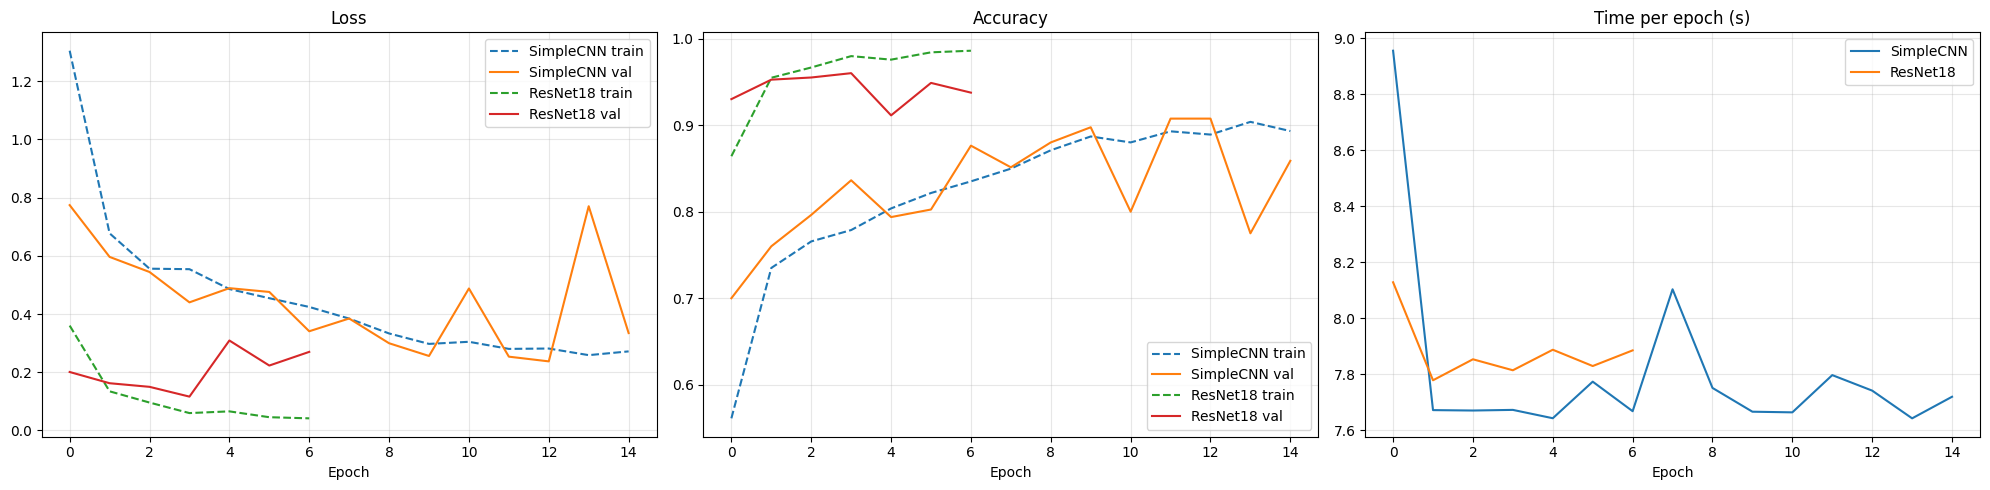

In [9]:
# 9. Обучения
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for name, h in histories.items():
        axes[0].plot(h["train_loss"], "--", label=f"{name} train")
        axes[0].plot(h["val_loss"],   "-",  label=f"{name} val")
        axes[1].plot(h["train_acc"],  "--", label=f"{name} train")
        axes[1].plot(h["val_acc"],    "-",  label=f"{name} val")
        axes[2].plot(h["time"], label=name)
    for ax, t in zip(axes, ["Loss", "Accuracy", "Time per epoch (s)"]):
        ax.set_title(t); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})

Строю графики, чтобы сравнить обучение SimpleCNN и ResNet18. На них отображаются ошибка (Loss) и точность (Accuracy) на обучающей и проверочной выборках, а также время одной эпохи. По этим графикам можно оценить, как быстро обучаются модели, улучшается ли качество на валидации и есть ли признаки переобучения.


SimpleCNN — Test Accuracy: 0.8408
              precision    recall  f1-score   support

      glioma     0.9541    0.6233    0.7540       300
  meningioma     0.7759    0.7733    0.7746       300
     notumor     0.7909    0.9833    0.8767       300
   pituitary     0.8886    0.9833    0.9335       300

    accuracy                         0.8408      1200
   macro avg     0.8524    0.8408    0.8347      1200
weighted avg     0.8524    0.8408    0.8347      1200



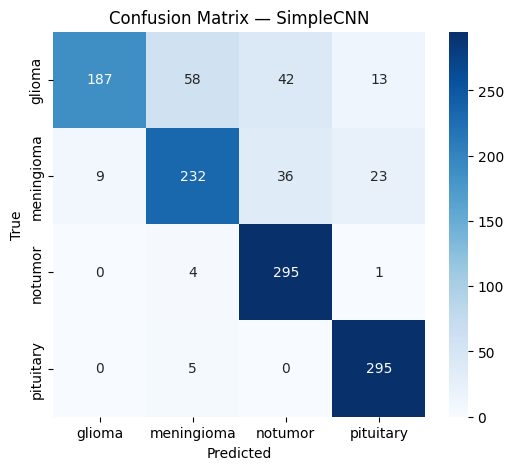


ResNet18 — Test Accuracy: 0.9392
              precision    recall  f1-score   support

      glioma     0.9644    0.8133    0.8825       300
  meningioma     0.8969    0.9567    0.9258       300
     notumor     0.9373    0.9967    0.9661       300
   pituitary     0.9643    0.9900    0.9770       300

    accuracy                         0.9392      1200
   macro avg     0.9407    0.9392    0.9378      1200
weighted avg     0.9407    0.9392    0.9378      1200



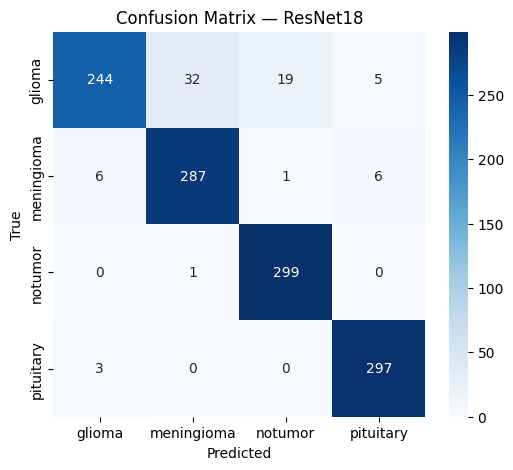

In [10]:
# 10. Оценка на тестовой выборке
def full_report(model, loader, title):
    _, acc, y_true, y_pred = evaluate(model, loader, nn.CrossEntropyLoss())
    print(f"\n{title} — Test Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=classes, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

res_cnn    = full_report(cnn_model,    test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

Проверяю обе обученные модели на отдельной тестовой выборке. Функция выводит общую точность и отчёт с precision, recall и F1-score для каждого класса. Затем строится матрица ошибок: по строкам указаны истинные классы, по столбцам — предсказанные. Значения на диагонали означают правильные предсказания, а остальные показывают, какие классы модель путает. Тестовые данные здесь используются для итоговой оценки, а не для обучения.

In [11]:
# 11. Сводная таблица сравнения
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(res["y_true"], res["y_pred"], average="macro", zero_division=0)
    return {"Model": name, "Params": f"{count_params(model):,}",
            "Best val acc": f"{max(hist['val_acc']):.4f}", "Test acc": f"{res['acc']:.4f}",
            "Macro F1": f"{f:.4f}", "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
            "Epochs trained": len(hist["time"])}

pd.DataFrame([summarize("SimpleCNN", hist_cnn, res_cnn, cnn_model),
              summarize("ResNet18",  hist_resnet, res_resnet, resnet_model)]).set_index("Model")

,Params,Best val acc,Test acc,Macro F1,Mean epoch time (s),Epochs trained
Model,,,,,,
SimpleCNN,"2,339,972",0.9075,0.8408,0.8347,7.8,15
ResNet18,"11,178,564",0.9600,0.9392,0.9378,7.9,7


Собираю основные результаты в одну таблицу для удобного сравнения моделей. В неё входят количество обучаемых параметров, лучшая точность на валидации, точность на тесте, средний Macro F1, среднее время эпохи и фактическое число пройденных эпох. Macro F1 усредняет F1-score по всем классам с одинаковым весом, поэтому помогает увидеть качество не только на наиболее частом классе. По таблице можно сравнить качество и вычислительные затраты двух подходов.

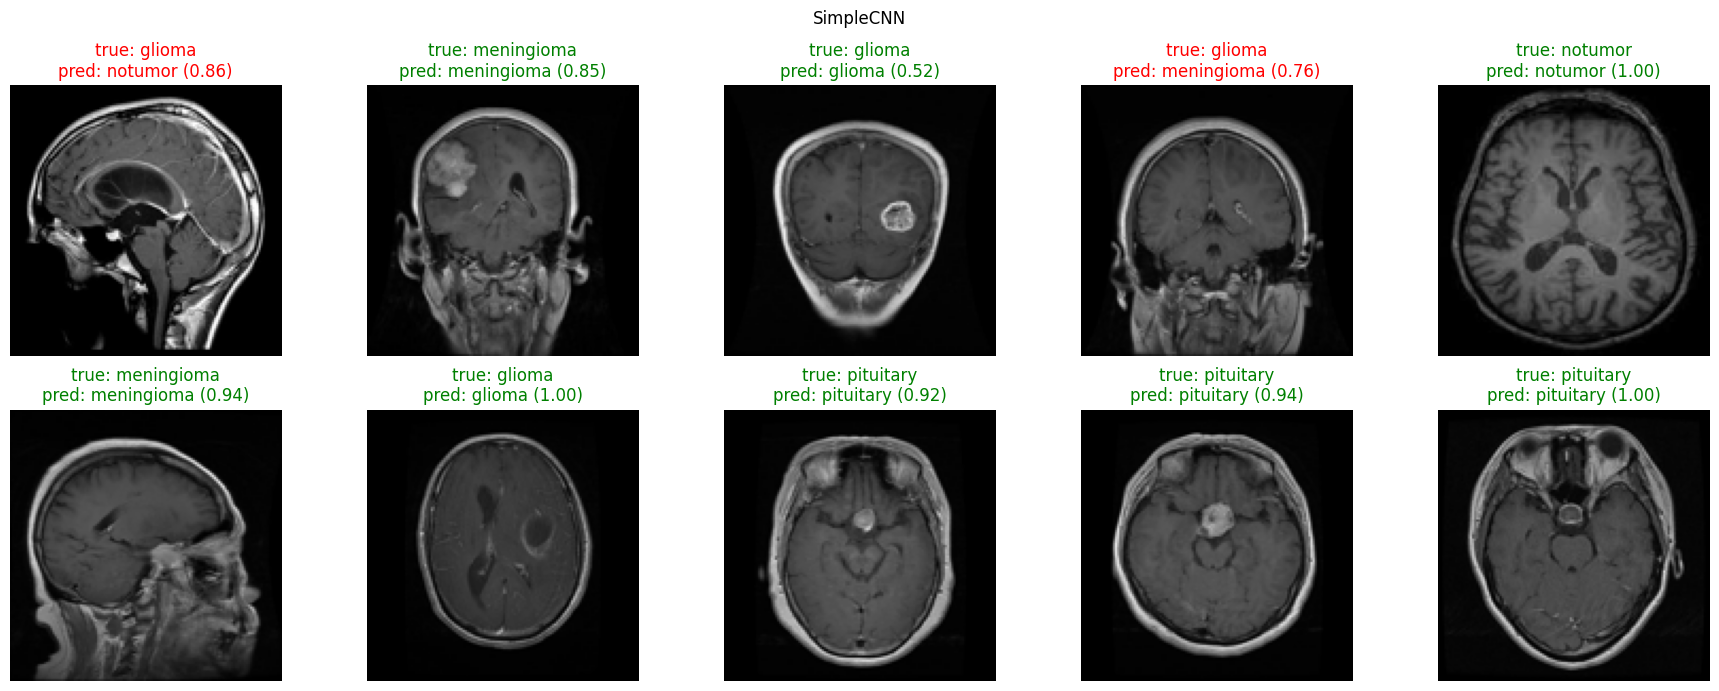

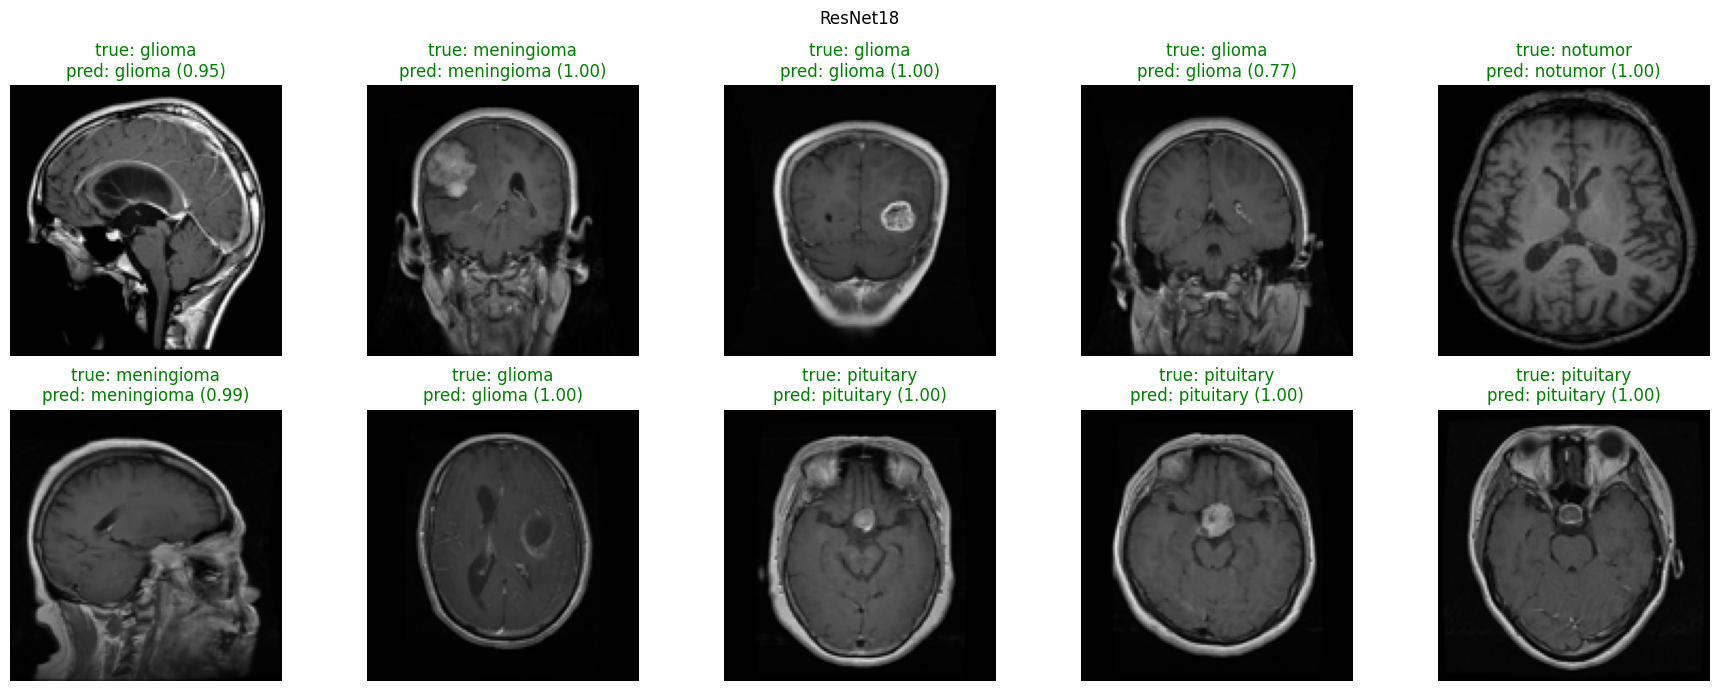

In [12]:
# 12. Примеры предсказаний
@torch.no_grad()
def show_predictions(model, images, labels, idxs, title):
    model.eval()
    fig, axes = plt.subplots(2, len(idxs) // 2, figsize=(18, 7))
    for ax, i in zip(axes.ravel(), idxs):
        prob = torch.softmax(model(eval_tfms(images[i]).unsqueeze(0).to(device)), dim=1).cpu().numpy().ravel()
        pred = int(prob.argmax())
        ax.imshow(images[i])
        ax.set_title(f"true: {classes[labels[i]]}\npred: {classes[pred]} ({prob[pred]:.2f})",
                     color="green" if pred == labels[i] else "red")
        ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

idxs = np.random.RandomState(0).choice(len(X_test), 10, replace=False)   # одни и те же картинки для обеих сетей
show_predictions(cnn_model,    X_test, y_test_enc, idxs, "SimpleCNN")
show_predictions(resnet_model, X_test, y_test_enc, idxs, "ResNet18")

Показываю примеры предсказаний моделей на изображениях из тестовой выборки. Для каждого изображения сеть рассчитывает оценки классов, а Softmax переводит их в вероятностное распределение; выбирается класс с наибольшей оценкой. В заголовке отображаются истинный и предсказанный классы, а цвет помогает заметить правильные и ошибочные ответы. Обе модели проверяются на одинаковых примерах. Значение Softmax — это уверенность модели в рамках её расчёта, а не медицинское подтверждение диагноза.